<a href="https://colab.research.google.com/github/riyajethwani2004-code/Image_Pixel_Manipulator/blob/main/image_pixel_manipulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎨 PixelForge: Image Pixel Manipulator (Synthetic Images)
**Treat an image as a 3D NumPy array (height × width × RGB), then create, crop, recolor and filter it using only NumPy.**

Every run generates *brand-new random images*. Set `SEED` to any number to reproduce a result exactly.

| Part | What it covers |
|---|---|
| 1 | Blank canvas: `np.zeros`, `np.ones`, `np.full` |
| 2 | Colour blocks, stripes and random noise with 3D slicing |
| 3 | Crop, flip (negative-step slicing) and R/G/B channel extraction |
| 4 | Brighten / darken with `astype(float32)` and a boolean mask for bright pixels |
| 5 | Memory comparison: `uint8` vs `float32` vs `float64` with `nbytes`, shown with `plt.imshow` |
| 6 | 🧰 Filter library written from scratch (Sobel edges, blur, sepia, glitch, pixelate...) |
| 7 | Save results to PNG |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- RANDOMNESS CONTROL ----------
SEED = None   # None = fresh random output every run | or set e.g. SEED = 42 to reproduce
seed = int(np.random.SeedSequence().entropy % 10**8) if SEED is None else SEED
rng = np.random.default_rng(seed)
print(f"🎲 Seed for this run: {seed}   (set SEED = {seed} to recreate everything below)")

H = W = 200   # image size

def rand_color():
    """Random RGB colour as a uint8 array of shape (3,)."""
    return rng.integers(0, 256, 3).astype(np.uint8)

def show(images, titles=None, cols=None, size=3.2, suptitle=None):
    """Display a list of images in a tidy grid."""
    n = len(images); cols = cols or n; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.1))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            ax.imshow(images[i])
            if titles: ax.set_title(titles[i], fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    plt.tight_layout(); plt.show()

🎲 Seed for this run: 49114214   (set SEED = 49114214 to recreate everything below)


## Part 1: Blank canvas with `np.zeros` / `np.ones` / `np.full`
An image is just a 3D array of shape `(height, width, 3)` holding `uint8` values from 0 to 255.

shape: (200, 200, 3) | dtype: uint8 | background colour: [223 221 243]


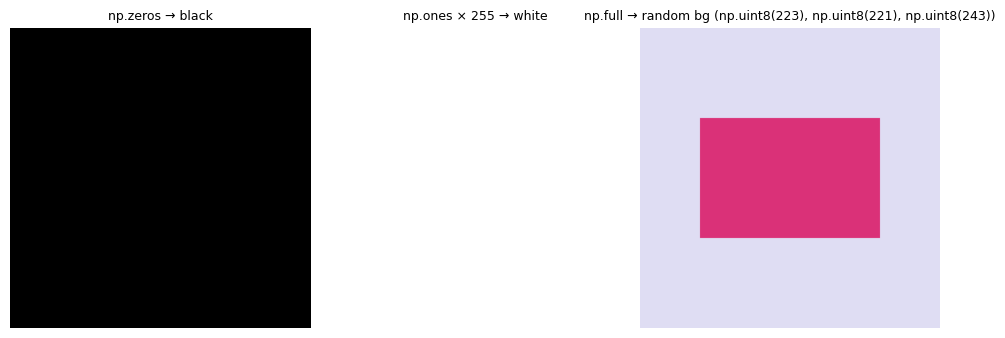

In [2]:
blank = np.zeros((H, W, 3), dtype=np.uint8)           # all black
bg = rand_color()
white = np.ones((H, W, 3), dtype=np.uint8) * 255       # np.ones → all 1s, ×255 = white
solid = np.full((H, W, 3), bg, dtype=np.uint8)         # np.full → filled with a random colour

# Fill a region with np.full: paste a random-coloured rectangle into the canvas
region = np.full((80, 120, 3), rand_color(), dtype=np.uint8)
solid[60:140, 40:160] = region

print("shape:", blank.shape, "| dtype:", blank.dtype, "| background colour:", bg)
show([blank, white, solid], ["np.zeros → black", "np.ones × 255 → white", f"np.full → random bg {tuple(bg)}"])

## Part 2: Colour blocks, stripes & noise with 3D slicing
`img[rows, cols, channel]`: the third index picks R (0), G (1) or B (2).

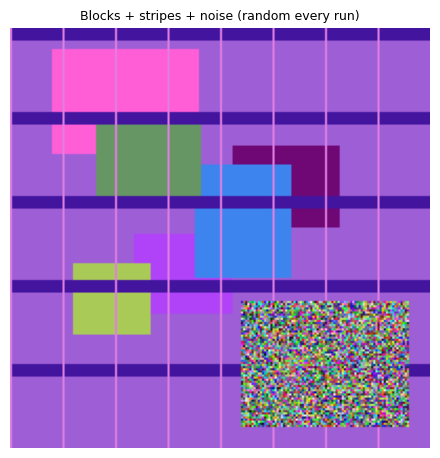

In [3]:
img = np.full((H, W, 3), rand_color(), dtype=np.uint8)

# (a) the brief's classic: max out only the RED channel inside a block
img[10:60, 20:90, 0] = 255

# (b) random coloured blocks
for _ in range(5):
    y, x = rng.integers(0, 150, 2)
    h, w = rng.integers(20, 55, 2)
    img[y:y+h, x:x+w] = rand_color()

# (c) stripes using step slicing: horizontal bands + vertical pinstripes
stripe_c = rand_color()
for y in range(0, H, 40):
    img[y:y+6, :] = stripe_c
img[:, ::25] = rand_color()          # step slicing = vertical pinstripes

# (d) np.random: a patch of pure random noise
img[130:190, 110:190] = rng.integers(0, 256, (60, 80, 3), dtype=np.uint8)

show([img], ["Blocks + stripes + noise (random every run)"], size=4.5)

## Part 3: Crop, flip (negative-step slicing) & channel extraction

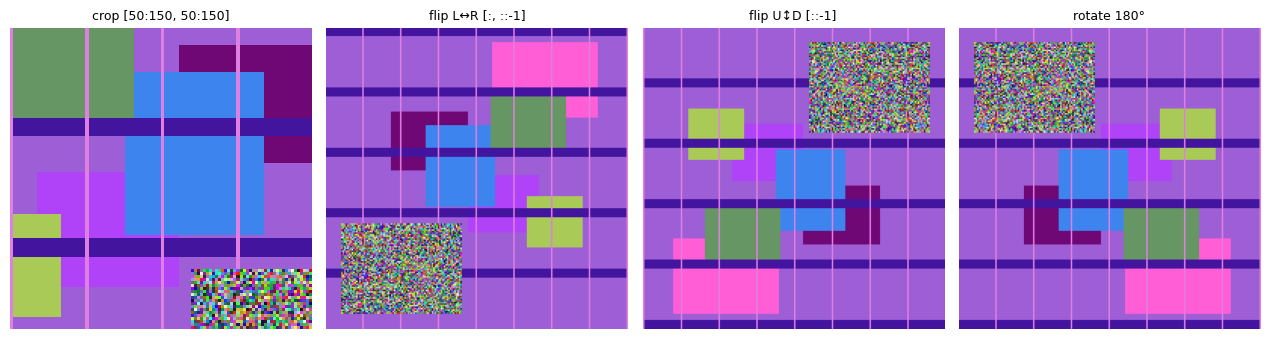

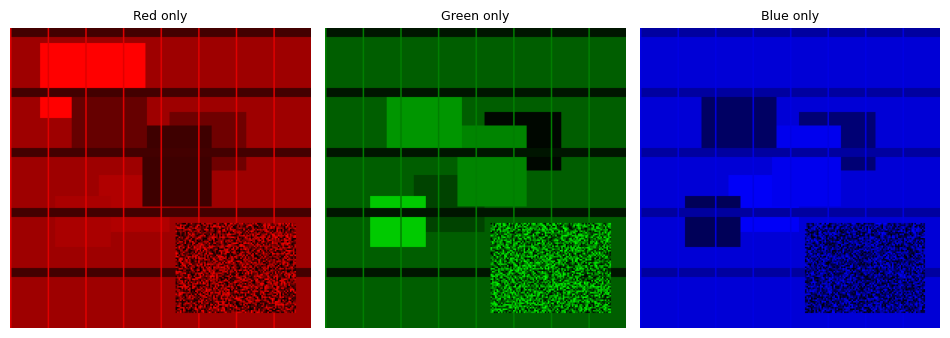

In [4]:
crop      = img[50:150, 50:150]        # crop centre
flip_lr   = img[:, ::-1]               # mirror left-right
flip_ud   = img[::-1]                  # mirror top-bottom
rot180    = img[::-1, ::-1]            # both = 180° rotation

def only_channel(a, c):
    out = np.zeros_like(a); out[..., c] = a[..., c]; return out

R, G, B = (only_channel(img, c) for c in range(3))

show([crop, flip_lr, flip_ud, rot180], ["crop [50:150, 50:150]", "flip L↔R [:, ::-1]", "flip U↕D [::-1]", "rotate 180°"])
show([R, G, B], ["Red only", "Green only", "Blue only"])

## Part 4: Brighten / darken (float32 round-trip) + boolean masks
We cast to `float32` before multiplying so values can go above 255 safely, then `np.clip` to 0-255 and cast back to `uint8`.

Bright pixels (> 155): 5,915 of 40,000  =  14.8%


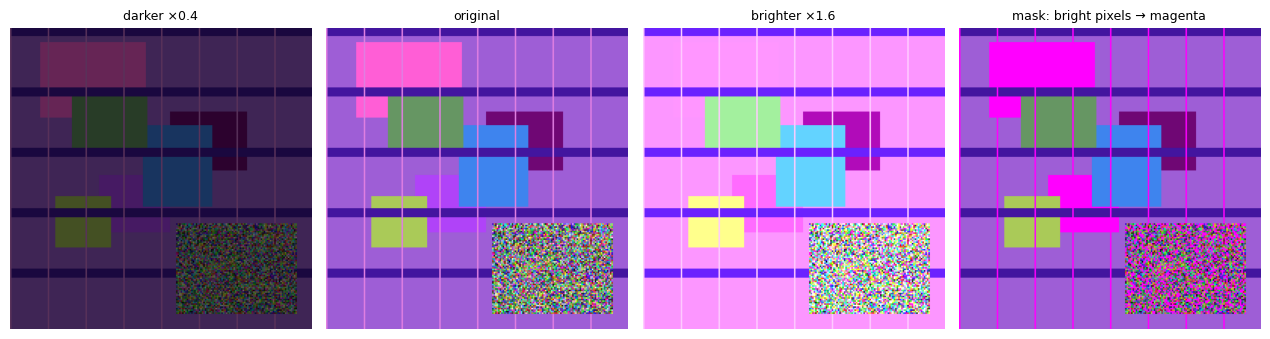

In [5]:
def brightness(a, factor):
    """uint8 → float32 → multiply → clip to 0-255 → uint8."""
    return np.clip(a.astype(np.float32) * factor, 0, 255).astype(np.uint8)

brighter, darker = brightness(img, 1.6), brightness(img, 0.4)

# Boolean mask: find the brightest ~20% of pixels and highlight them
gray = img.mean(axis=2)
THRESH = np.percentile(gray, 80)      # adaptive threshold, works for any random image
mask = gray > THRESH
highlight = img.copy()
highlight[mask] = [255, 0, 255]       # magenta where bright
print(f"Bright pixels (> {THRESH:.0f}): {mask.sum():,} of {mask.size:,}  =  {mask.mean()*100:.1f}%")

show([darker, img, brighter, highlight], ["darker ×0.4", "original", "brighter ×1.6", "mask: bright pixels → magenta"])

## Part 5: Memory: `uint8` vs `float32` vs `float64`

uint8   :   120,000 bytes  (1× uint8)
float32 :   480,000 bytes  (4× uint8)
float64 :   960,000 bytes  (8× uint8)


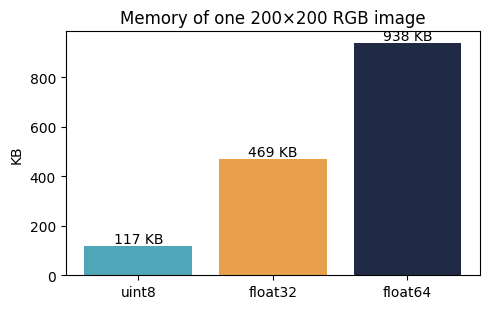

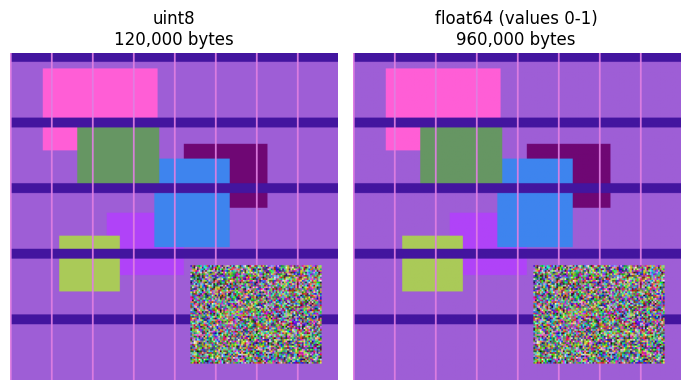

In [6]:
f32, f64 = img.astype(np.float32) / 255, img.astype(np.float64) / 255
sizes = {"uint8": img.nbytes, "float32": f32.nbytes, "float64": f64.nbytes}
for k, v in sizes.items():
    print(f"{k:8s}: {v:>9,} bytes  ({v/sizes['uint8']:.0f}× uint8)")

plt.figure(figsize=(5, 3.2))
bars = plt.bar(sizes.keys(), [v/1024 for v in sizes.values()], color=["#4FA6B8", "#E8A04C", "#202A44"])
plt.bar_label(bars, fmt="%.0f KB"); plt.ylabel("KB"); plt.title("Memory of one 200×200 RGB image")
plt.tight_layout(); plt.show()

# Show both versions with plt.imshow: they look identical but cost very different memory
fig, ax = plt.subplots(1, 2, figsize=(7, 3.8))
ax[0].imshow(img); ax[0].set_title(f"uint8\n{img.nbytes:,} bytes")
ax[1].imshow(f64); ax[1].set_title(f"float64 (values 0-1)\n{f64.nbytes:,} bytes")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

---
## Part 6: 🧰 Filter library (built from scratch, NumPy only)
No OpenCV, no PIL, no SciPy. Edge detection and blur are done with *shifted slices*.

/tmp/ipykernel_767/2846057680.py:28: UserWarning: Glyph 129520 (\N{TOOLBOX}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129520 (\N{TOOLBOX}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


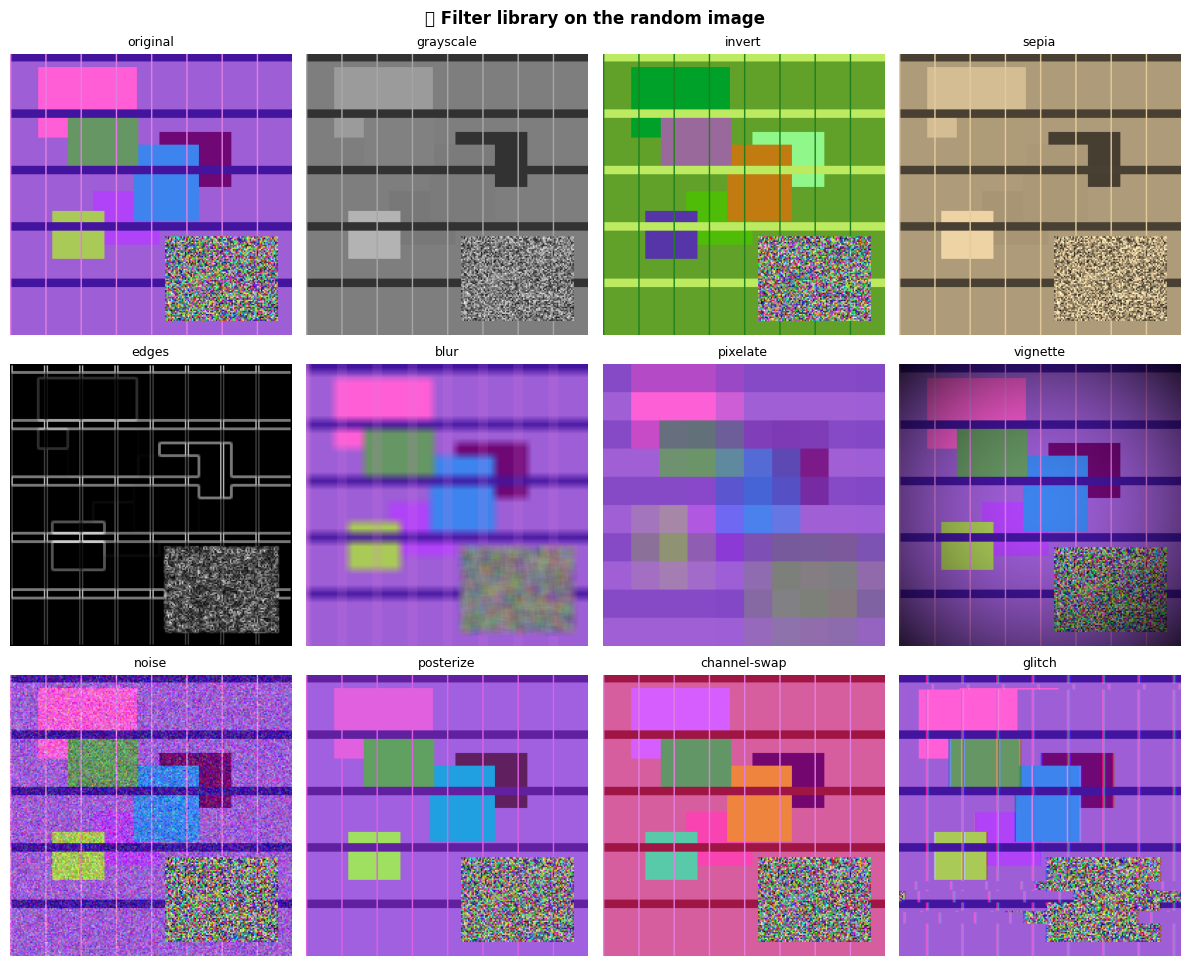

In [7]:
def to_gray(a):          return a.astype(np.float32) @ np.array([0.299, 0.587, 0.114], np.float32)
def stack3(g):           return np.clip(np.stack([g] * 3, axis=-1), 0, 255).astype(np.uint8)

def f_grayscale(a, rng): return stack3(to_gray(a))
def f_invert(a, rng):    return 255 - a
def f_sepia(a, rng):
    M = np.array([[.393, .769, .189], [.349, .686, .168], [.272, .534, .131]], np.float32)
    return np.clip(a.astype(np.float32) @ M.T, 0, 255).astype(np.uint8)

def f_edges(a, rng):     # Sobel operator via slicing
    g = to_gray(a)
    gx = (g[:-2, 2:] + 2*g[1:-1, 2:] + g[2:, 2:]) - (g[:-2, :-2] + 2*g[1:-1, :-2] + g[2:, :-2])
    gy = (g[2:, :-2] + 2*g[2:, 1:-1] + g[2:, 2:]) - (g[:-2, :-2] + 2*g[:-2, 1:-1] + g[:-2, 2:])
    mag = np.pad(np.hypot(gx, gy), 1)
    return stack3(mag / (mag.max() + 1e-6) * 255)

def f_blur(a, rng, k=7): # box blur = average of k×k shifted copies
    p = np.pad(a.astype(np.float32), ((k//2,)*2, (k//2,)*2, (0, 0)), mode="edge")
    out = sum(p[i:i+a.shape[0], j:j+a.shape[1]] for i in range(k) for j in range(k)) / k**2
    return out.astype(np.uint8)

def f_pixelate(a, rng):  # reshape trick: average each block, then repeat it
    b = int(rng.choice([5, 8, 10, 20])); h, w, _ = a.shape; h2, w2 = h//b*b, w//b*b
    small = a[:h2, :w2].reshape(h2//b, b, w2//b, b, 3).mean(axis=(1, 3))
    return np.repeat(np.repeat(small, b, 0), b, 1).astype(np.uint8)

def f_vignette(a, rng):
    h, w, _ = a.shape; yy, xx = np.ogrid[:h, :w]
    d = np.hypot(yy - h/2, xx - w/2) / np.hypot(h/2, w/2)
    return (a * (1 - 0.8 * d**2)[..., None]).astype(np.uint8)

def f_noise(a, rng):
    return np.clip(a + rng.normal(0, 30, a.shape), 0, 255).astype(np.uint8)

def f_posterize(a, rng): return ((a // 64) * 64 + 32).astype(np.uint8)
def f_swap(a, rng):      return a[..., rng.permutation(3)]          # shuffle R/G/B channels

def f_glitch(a, rng):
    out = a.copy()
    for c in range(3):                                              # RGB-split
        out[..., c] = np.roll(a[..., c], int(rng.integers(-8, 9)), axis=1)
    for _ in range(6):                                              # shifted row bands
        y = int(rng.integers(0, a.shape[0] - 10)); hh = int(rng.integers(3, 12))
        out[y:y+hh] = np.roll(out[y:y+hh], int(rng.integers(-30, 31)), axis=1)
    return out

FILTERS = {"grayscale": f_grayscale, "invert": f_invert, "sepia": f_sepia, "edges": f_edges,
           "blur": f_blur, "pixelate": f_pixelate, "vignette": f_vignette, "noise": f_noise,
           "posterize": f_posterize, "channel-swap": f_swap, "glitch": f_glitch}

names = list(FILTERS)
show([img] + [FILTERS[n](img, rng) for n in names], ["original"] + names, cols=4, size=3,
     suptitle="🧰 Filter library on the random image")

## Part 7: 💾 Save outputs (so your GitHub repo shows results)

In [8]:
os.makedirs("outputs", exist_ok=True)
plt.imsave(f"outputs/original_{seed}.png", img)
for n in names:
    plt.imsave(f"outputs/{n}_{seed}.png", FILTERS[n](img, rng))
print("Saved:", sorted(os.listdir("outputs")))
print("\n✅ Done. Re-run the whole notebook for new random images, or set SEED to reproduce this run.")

Saved: ['blur_49114214.png', 'channel-swap_49114214.png', 'edges_49114214.png', 'glitch_49114214.png', 'grayscale_49114214.png', 'invert_49114214.png', 'noise_49114214.png', 'original_49114214.png', 'pixelate_49114214.png', 'posterize_49114214.png', 'sepia_49114214.png', 'vignette_49114214.png']

✅ Done. Re-run the whole notebook for new random images, or set SEED to reproduce this run.
